# 02 · Exploratory data analysis

Having repaired the data and built the amino-acid features, I'm ready to do some exploration: the distributions of the amino-acid frequencies and of `Ncodons`, how the features correlate, and how they differ between taxonomic groups and genome compartments. I use all 13,028 rows here, rare classes included; the class filter comes in `03_preprocessing`.

One finding here affects the rest of the project: for about a fifth of the rows, the 21 "amino-acid" frequencies are not amino-acid frequencies at all (see the section on correlations).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import codon_utils

plt.rcParams['figure.dpi'] = 72  # small inline images keep the notebook file small

# the repaired raw data (see 01_wrangling) plus the 21 amino-acid frequencies
raw = codon_utils.read_raw('../data/raw/codon_usage.csv')
codon_usage = pd.concat([raw, codon_utils.amino_features(raw)], axis=1)

codon_list = codon_utils.CODONS
amino_list = codon_utils.AMINOS
kingdoms = sorted(codon_usage['kingdom'].unique())

One interesting thing to examine is the distribution of each amino acid across the entire dataset.

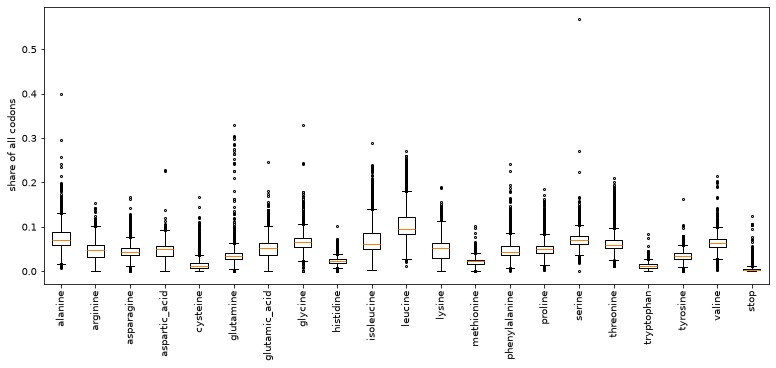

In [2]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.boxplot(codon_usage[amino_list].to_numpy(), tick_labels=amino_list, flierprops={'markersize': 2})
ax.tick_params(axis='x', labelrotation=90)
ax.set_ylabel('share of all codons')
plt.show()

Clearly, the amino acids have quite different distributions: leucine is the most common and the most variable; tryptophan, cysteine and the stop signals are rare. All of them have a pronounced right skew, which isn't unexpected for proportions near zero. But some of the outliers are quite surprising: there is one organism for which over half of all codons encode serine. I wonder what that is?

In [3]:
print(codon_usage['SpeciesName'].loc[codon_usage['serine'] == codon_usage['serine'].max()], codon_usage['serine'].max())

8734    Phragmatopoma californica
Name: SpeciesName, dtype: str 0.5677399999999999


Well, that's interesting. It's *Phragmatopoma californica*, a marine polychaete worm (https://en.wikipedia.org/wiki/Phragmatopoma_californica). Its entry rests on only 2,015 codons, so a handful of genes (perhaps the serine-rich proteins of the cement it uses to build its tube) determine its frequencies.

That raises a general point: a frequency is only as reliable as the number of codons behind it. How much does `Ncodons` vary between groups?

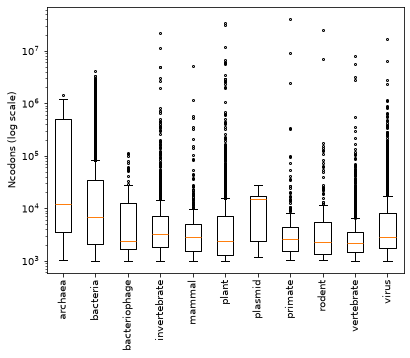

In [4]:
# the number of codons behind each row, by group (log scale: it spans 1,000 to 40 million)
fig, ax = plt.subplots()
ax.boxplot([codon_usage.loc[codon_usage['kingdom'] == k, 'Ncodons'] for k in kingdoms],
           tick_labels=kingdoms, flierprops={'markersize': 2})
ax.set_yscale('log')
ax.tick_params(axis='x', labelrotation=90)
ax.set_ylabel('Ncodons (log scale)')
plt.show()

A great deal. Every row has at least 1,000 codons, the median is about 2,900, and the largest, the human nuclear genome, has over 40 million; hence the log scale. The group medians are lowest for the vertebrate divisions and plants (around 2,200 to 2,400, much of it mitochondrial and chloroplast DNA, whose genomes hold only a few dozen genes) and highest for bacteria and archaea (about 6,700 and 12,000). Let's examine the distribution with respect to DNA type:

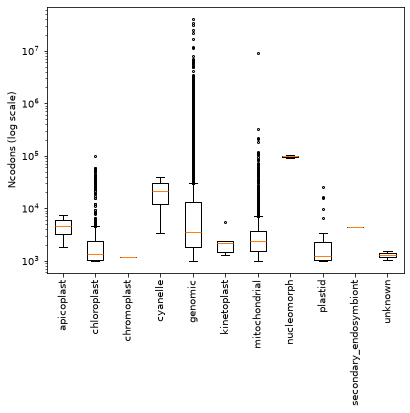

In [5]:
dna_types = sorted(codon_usage['dna_type'].unique())
fig, ax = plt.subplots()
ax.boxplot([codon_usage.loc[codon_usage['dna_type'] == t, 'Ncodons'] for t in dna_types],
           tick_labels=dna_types, flierprops={'markersize': 2})
ax.set_yscale('log')
ax.tick_params(axis='x', labelrotation=90)
ax.set_ylabel('Ncodons (log scale)')
plt.show()

These boxplots look a little odd: some of them are entirely collapsed into a line. The value counts explain why:

In [6]:
codon_usage['dna_type'].value_counts()

dna_type
genomic                   9267
mitochondrial             2899
chloroplast                816
plastid                     31
kinetoplast                  5
cyanelle                     2
unknown                      2
nucleomorph                  2
apicoplast                   2
secondary_endosymbiont       1
chromoplast                  1
Name: count, dtype: int64

Several of these categories have so few members that there's no distribution to speak of: one chromoplast, one secondary endosymbiont, two each of cyanelle, nucleomorph and apicoplast. It will be necessary to exclude this handful of observations from any models (`03_preprocessing`), since no model can learn a class from one or two examples, or be fairly tested on it.

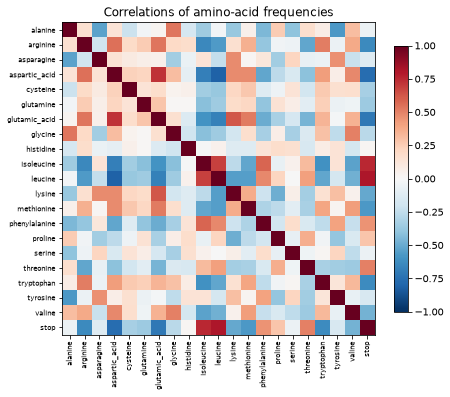

In [7]:
def corr_heatmap(cols, title):
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(codon_usage[cols].corr(), cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=7)
    ax.set_yticks(range(len(cols)), cols, fontsize=7)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.show()


corr_heatmap(amino_list, 'Correlations of amino-acid frequencies')

With the duplicate *start* column gone, no pair of features is perfectly correlated. What stands out is a cluster: leucine, isoleucine and the stop signals are strongly correlated with one another, and aspartic acid is strongly negatively correlated with leucine. In 2022 I wondered whether the correlation with the stop codons meant that leucine and isoleucine are more common in shorter genes. But a correlation computed over all rows pools very different kinds of genome; are these properties of genes, or of the mix of rows?

In [8]:
pairs = [('leucine', 'isoleucine'), ('leucine', 'stop'), ('isoleucine', 'stop'), ('aspartic_acid', 'leucine')]
subsets = {'all rows': codon_usage,
           'genomic rows': codon_usage[codon_usage['dna_type'] == 'genomic'],
           'mitochondrial rows': codon_usage[codon_usage['dna_type'] == 'mitochondrial']}
pd.DataFrame({name: [d[a].corr(d[b]) for a, b in pairs] for name, d in subsets.items()},
             index=[f'{a} / {b}' for a, b in pairs]).round(2)

,all rows,genomic rows,mitochondrial rows
leucine / isoleucine,0.68,0.03,-0.21
leucine / stop,0.81,-0.05,0.31
isoleucine / stop,0.75,0.09,0.17
aspartic_acid / leucine,-0.81,-0.16,-0.68


In [9]:
codon_usage[codon_usage['dna_type'].isin(['genomic', 'mitochondrial'])].groupby('dna_type')[['stop', 'leucine']].median()

,stop,leucine
dna_type,,
genomic,0.00279,0.08945
mitochondrial,0.02806,0.16359


Mostly the mix. The median frequency of the stop group is about ten times higher in mitochondrial rows than in genomic rows (0.028 against 0.0028), and leucine is higher too (0.16 against 0.09), so pooling the compartments manufactures strong correlations between the features that differ between them. Within genomic rows, the leucine–isoleucine, leucine–stop and isoleucine–stop correlations are close to zero; within mitochondrial rows they are weak, or even reversed. Aspartic acid and leucine are only weakly correlated among genomic rows (−0.16), though they remain strongly correlated among mitochondrial rows (−0.68). The pooled correlations, then, largely describe differences *between* compartments, not how amino acids vary together *within* a genome: a close cousin of Simpson's paradox.

That leaves a stranger question: why would mitochondrial rows contain ten times as many stop codons? A gene has one stop codon, at its end, so this would imply genes a tenth as long, which mitochondrial genes are not.

In [10]:
# Which rows follow the standard genetic code? In animal mitochondria UGA codes for
# tryptophan (not stop) and AUA for methionine; vertebrate mitochondria avoid AGA/AGG.
animal = ['vertebrate', 'mammal', 'rodent', 'primate', 'invertebrate']
mito = codon_usage['dna_type'] == 'mitochondrial'
group = pd.Series('other', index=codon_usage.index)
group[codon_usage['dna_type'] == 'genomic'] = 'nuclear (genomic)'
group[codon_usage['dna_type'] == 'chloroplast'] = 'chloroplast'
group[mito & codon_usage['kingdom'].isin(animal)] = 'animal mitochondria'
group[mito & (codon_usage['kingdom'] == 'plant')] = 'plant mitochondria'
codes = codon_usage.assign(group=group, AGA_AGG=codon_usage['AGA'] + codon_usage['AGG'],
                           UGA_over_UGG=codon_usage['UGA'] > codon_usage['UGG'])
codes = codes[codes['group'] != 'other']
table = codes.groupby('group')[['UGA', 'UGG', 'AUA', 'AUG', 'AGA_AGG']].median()
table['share UGA > UGG'] = codes.groupby('group')['UGA_over_UGG'].mean()
table['rows'] = codes['group'].value_counts()
table.loc[['nuclear (genomic)', 'chloroplast', 'plant mitochondria', 'animal mitochondria']].round(4)

,UGA,UGG,AUA,AUG,AGA_AGG,share UGA > UGG,rows
group,,,,,,,
nuclear (genomic),0.0008,0.0132,0.0101,0.0239,0.0190,0.0090,9267
chloroplast,0.0009,0.0158,0.0242,0.0191,0.0214,0.0025,816
plant mitochondria,0.0014,0.0124,0.0254,0.0247,0.0193,0.3355,152
animal mitochondria,0.0255,0.0029,0.0342,0.0106,0.0004,0.9651,2747


The answer is that the genetic code is not quite universal. Animal mitochondria use their own variants (NCBI translation tables 2 for vertebrates and 5 for invertebrates). In both, UGA, a stop codon in the standard code, encodes tryptophan instead, and the table shows that it is used far more often than UGG, the standard tryptophan codon: UGA outnumbers UGG in 96.5% of animal-mitochondrial rows, against 0.9% of nuclear rows. AUA, isoleucine in the standard code, encodes methionine; and AGA and AGG, arginine in the standard code, are stops in vertebrate mitochondria, which accordingly almost never use them. Plant mitochondria mostly follow the standard code; the third of them in which UGA outnumbers UGG are probably fungal mitochondria, which CUTG files with the plants.

So for the animal mitochondria, 2,747 of the 12,963 rows that reach the models (21%), the 21 "amino-acid" features are really groups of codons that the *standard* code treats as synonymous, not amino-acid composition: the "stop" group there mostly counts tryptophan, and "isoleucine" includes a methionine codon. That accounts for the tenfold "stop" frequency.

Could I correct the features, translating each row with its own genetic code? Only by knowing each row's compartment and lineage, and those are precisely what the models are trying to predict; the corrected features would carry the answer inside them. So I keep the standard code, which is the only choice that doesn't leak the labels, and refer to the features as codon groups. Whether the models lean on the misnamed "stop" group is a fair question, and `04_modeling` tests it directly.

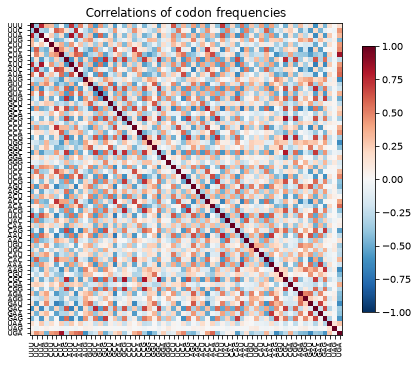

In [11]:
corr_heatmap(codon_list, 'Correlations of codon frequencies')

With 64 codons the heatmap shows plenty of structure (the checkering indicates that many codon frequencies are associated), but individual pairs are hard to read at this size, and, as the previous section showed, pooled correlations need careful reading.

## Leucine by group and compartment

The 2022 README compared leucine across taxonomic groups and found it more common among vertebrates than invertebrates. The same pooling problem applies. That plot included the plasmids and lumped all DNA types together, and the mix of DNA types differs sharply between groups:

In [12]:
compartments = ['genomic', 'mitochondrial', 'chloroplast']
sub = codon_usage[(codon_usage['kingdom'] != 'plasmid') & codon_usage['dna_type'].isin(compartments)]
pd.crosstab(sub['kingdom'], sub['dna_type'], normalize='index').loc[['vertebrate', 'invertebrate'], compartments].round(2)

dna_type,genomic,mitochondrial,chloroplast
kingdom,,,
vertebrate,0.22,0.78,0.0
invertebrate,0.69,0.31,0.0


More than three quarters of the vertebrate rows are mitochondrial, against under a third of the invertebrate rows, and we've just seen that mitochondrial rows have much more leucine. So the leucine plot has to be split by compartment (plasmids excluded):

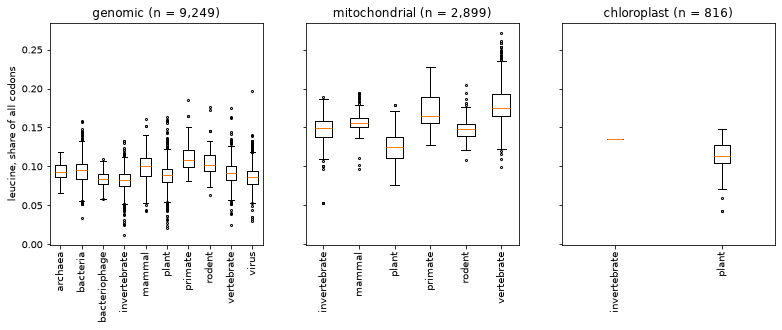

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, t in zip(axes, compartments):
    d = sub[sub['dna_type'] == t]
    groups = [k for k in kingdoms if (d['kingdom'] == k).any()]
    ax.boxplot([d.loc[d['kingdom'] == k, 'leucine'] for k in groups],
               tick_labels=groups, flierprops={'markersize': 2})
    ax.set_title(f'{t} (n = {len(d):,})')
    ax.tick_params(axis='x', labelrotation=90)
axes[0].set_ylabel('leucine, share of all codons')
plt.show()

In [14]:
sub.groupby(['kingdom', 'dna_type'])['leucine'].median().unstack('dna_type')[compartments].round(3)

dna_type,genomic,mitochondrial,chloroplast
kingdom,,,
archaea,0.093,NaN,NaN
bacteria,0.095,NaN,NaN
bacteriophage,0.084,NaN,NaN
invertebrate,0.082,0.150,0.136
mammal,0.101,0.156,NaN
plant,0.089,0.125,0.114
primate,0.108,0.165,NaN
rodent,0.101,0.148,NaN
vertebrate,0.091,0.175,NaN


Leucine frequency depends mainly on the compartment: the group medians run from 0.082 to 0.108 in genomic rows, and from 0.125 to 0.175 in mitochondrial rows. Within a compartment, the vertebrate–invertebrate gap is modest: medians of 0.091 against 0.082 in genomic rows, and 0.175 against 0.150 in mitochondrial rows. The 2022 comparison, then, mostly measured the difference in the mix (78% mitochondrial against 31%), not a difference between vertebrates and invertebrates. (The single invertebrate "chloroplast" in the right-hand panel is the *Toxoplasma* apicoplast that `03_preprocessing` removes.)

The same confounding applies to any feature compared across groups, because kingdom and DNA type are strongly associated: knowing that a row is mitochondrial already makes 'vertebrate' far more likely. The models in `04_modeling` predict each label separately from the same features, so some of what a kingdom model learns is, in effect, the compartment.